# 実験1 (ex001): 論文再現実験

本ノートブックでは，論文 **"Cheat Detection on Online Chess Games using Convolutional and Dense Neural Network"** (Reyhan Patria et al., ISRITI 2021) で提案された4種類のニューラルネットワークモデルを PyTorch で忠実に再現し，
Lichess Open Database + Lichess User API (`tosViolation`) + Stockfish により構築した 5,000 対局データセットで学習・評価する．

### 再現条件（論文 Section III・IV 準拠）
- **データセット**: 5,000 対局（Label 0: チートなし 2,500局 / Label 1: 白番チート 1,250局 / Label 2: 黒番チート 1,250局）
- **最大手数**: 80手（80プライ，不足分は 0 パディング）
- **データ分割**: Train 80%（4,000局；うち 10%=400局を Validation，残り 3,600局を学習に使用）/ Test 20%（1,000局）
- **学習設定**: 15 epochs，1エポックあたり 10 batches（`batch_size = 360`），Adam（`lr = 0.001`）
- **比較モデル**: `Unanalyzed Dense`, `Unanalyzed CNN`, `Analyzed Dense`, `Analyzed CNN`

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
from IPython.display import display

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / 'datasets').exists() else cwd.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ex001.model import build_model
from ex001.utils import (
    CLASS_NAMES,
    create_dataloaders,
    load_and_split_dataset,
    plot_accuracy_comparison,
    plot_confusion_matrices,
    plot_validation_curves,
    set_seed,
    summarize_results,
    train_and_evaluate,
)

SEED = 42
set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'使用デバイス: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

使用デバイス: cuda
GPU: NVIDIA GeForce RTX 4080


C:\Users\watasaku\.matplotlib is not a writable directory
Matplotlib created a temporary cache directory at C:\Users\watasaku\AppData\Local\Temp\matplotlib-272920mo because there was an issue with the default path (C:\Users\watasaku\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
npz_path = PROJECT_ROOT / 'datasets' / 'chess_cheat_dataset.npz'
meta_path = PROJECT_ROOT / 'datasets' / 'metadata.csv'

meta_df = pd.read_csv(meta_path)
print('=== データセット概要 ===')
print(f'総対局数: {len(meta_df)}')
print('クラス別対局数:')
print(meta_df['label'].value_counts().sort_index().rename({0: '0: Nobody cheats', 1: '1: White cheats', 2: '2: Black cheats'}))
print(f'ユニークチーター数: {meta_df.loc[meta_df["label"] > 0, "cheater_user"].nunique()} 名')
print(f'平均手数 (80プライ上限内): {meta_df["actual_plies"].mean():.2f} ± {meta_df["actual_plies"].std():.2f}')
print(f'元データから [%eval] 付き対局数: {int(meta_df["has_orig_eval"].sum())} / {len(meta_df)}')
display(meta_df.head(5))

=== データセット概要 ===
総対局数: 5000
クラス別対局数:
label
0: Nobody cheats    2500
1: White cheats     1250
2: Black cheats     1250
Name: count, dtype: int64
ユニークチーター数: 248 名
平均手数 (80プライ上限内): 62.20 ± 18.80
元データから [%eval] 付き対局数: 409 / 5000


,game_idx,label,cheater_user,has_orig_eval,actual_plies,site,date,event,white_elo,black_elo,time_control,termination
0,0,0,NaN,False,48,https://lichess.org/GHALP9gW,2021.08.01,Rated Rapid tournament https://lichess.org/tournament/cu9aqMOJ,1690,1672,600+0,Normal
1,1,0,NaN,False,25,https://lichess.org/AgNL5qg0,2021.08.01,Rated Rapid tournament https://lichess.org/tournament/cu9aqMOJ,1869,1872,600+0,Normal
2,2,0,NaN,False,80,https://lichess.org/ccTEEAog,2021.08.01,Rated Rapid tournament https://lichess.org/tournament/cu9aqMOJ,1694,1786,600+0,Time forfeit
3,3,2,jovianyeoh20,False,47,https://lichess.org/3Uuih1oB,2021.08.01,Rated Rapid tournament https://lichess.org/tournament/cu9aqMOJ,1851,1849,600+0,Normal
4,4,0,NaN,False,80,https://lichess.org/TSF5WCtu,2021.08.01,Rated Rapid tournament https://lichess.org/tournament/cu9aqMOJ,2064,2062,600+0,Normal


In [3]:
splits = load_and_split_dataset(npz_path, seed=SEED, use_extended_analyzed=False)
print('Train:', splits['X_board_train'].shape, splits['X_analyzed_train'].shape, np.bincount(splits['y_train']))
print('Val  :', splits['X_board_val'].shape, splits['X_analyzed_val'].shape, np.bincount(splits['y_val']))
print('Test :', splits['X_board_test'].shape, splits['X_analyzed_test'].shape, np.bincount(splits['y_test']))

train_loader, val_loader, test_loader = create_dataloaders(
    splits, train_batches_per_epoch=10, eval_batch_size=200
)
print(f'Train batch_size: {train_loader.batch_size}, batches/epoch: {len(train_loader)}')

Train: (3600, 80, 14, 8, 8) (3600, 80, 2) [1800  900  900]
Val  : (400, 80, 14, 8, 8) (400, 80, 2) [200 100 100]
Test : (1000, 80, 14, 8, 8) (1000, 80, 2) [500 250 250]
Train batch_size: 360, batches/epoch: 10


## 4モデルの学習と評価
論文 Fig. 5 に基づく4種類のモデルを順番に学習・評価する．

In [4]:
model_names = [
    'Unanalyzed Dense',
    'Unanalyzed CNN',
    'Analyzed Dense',
    'Analyzed CNN',
]

results = []
for name in model_names:
    set_seed(SEED)
    model = build_model(name, num_classes=3, dropout_p=0.2)
    res = train_and_evaluate(
        model=model,
        model_name=name,
        train_loader=train_loader,
        val_loader=val_loader,
        test_loader=test_loader,
        device=device,
        epochs=15,
        lr=0.001,
    )
    results.append(res)
    print(f'--- {name} テスト評価結果 ---')
    print(f'Test Acc: {res["test_acc"]*100:.2f}% | Macro F1: {res["f1_macro"]*100:.2f}% | Time: {res["elapsed_sec"]:.2f}s')
    rep_df = pd.DataFrame(res['classification_report']).T
    display(rep_df.round(4))
    torch.cuda.empty_cache()

--- Unanalyzed Dense テスト評価結果 ---
Test Acc: 41.70% | Macro F1: 36.00% | Time: 9.57s
--- Unanalyzed CNN テスト評価結果 ---
Test Acc: 49.80% | Macro F1: 24.31% | Time: 12.93s
--- Analyzed Dense テスト評価結果 ---
Test Acc: 43.50% | Macro F1: 35.94% | Time: 9.95s
--- Analyzed CNN テスト評価結果 ---
Test Acc: 50.00% | Macro F1: 22.22% | Time: 13.26s


[Analyzed CNN]: 100%|##########| 15/15 [00:13<00:00,  1.13it/s, train_acc=0.5006, val_acc=0.5000, val_loss=1.0326]


,precision,recall,f1-score,support
Nobody cheats,0.5251,0.5860,0.5539,500.000
White cheats,0.2929,0.2320,0.2589,250.000
Black cheats,0.2705,0.2640,0.2672,250.000
accuracy,0.4170,0.4170,0.4170,0.417
macro avg,0.3628,0.3607,0.3600,1000.000
weighted avg,0.4034,0.4170,0.4085,1000.000


,precision,recall,f1-score,support
Nobody cheats,0.5036,0.978,0.6649,500.000
White cheats,0.0000,0.000,0.0000,250.000
Black cheats,0.3103,0.036,0.0645,250.000
accuracy,0.4980,0.498,0.4980,0.498
macro avg,0.2713,0.338,0.2431,1000.000
weighted avg,0.3294,0.498,0.3486,1000.000


,precision,recall,f1-score,support
Nobody cheats,0.5192,0.6500,0.5773,500.000
White cheats,0.3154,0.1880,0.2356,250.000
Black cheats,0.2800,0.2520,0.2653,250.000
accuracy,0.4350,0.4350,0.4350,0.435
macro avg,0.3715,0.3633,0.3594,1000.000
weighted avg,0.4084,0.4350,0.4138,1000.000


,precision,recall,f1-score,support
Nobody cheats,0.5000,1.0000,0.6667,500.0
White cheats,0.0000,0.0000,0.0000,250.0
Black cheats,0.0000,0.0000,0.0000,250.0
accuracy,0.5000,0.5000,0.5000,0.5
macro avg,0.1667,0.3333,0.2222,1000.0
weighted avg,0.2500,0.5000,0.3333,1000.0


In [5]:
summary_df = summarize_results(results)
summary_csv_path = PROJECT_ROOT / 'ex001' / 'results_summary.csv'
summary_df.to_csv(summary_csv_path, index=False, encoding='utf-8')
print('=== ex001 全モデル性能比較サマリ ===')
display(summary_df.round(2))

img_dir = PROJECT_ROOT / 'report' / 'img'
plot_validation_curves(results, img_dir / 'ex001_val_accuracy.png')
plot_accuracy_comparison(summary_df, img_dir / 'ex001_train_vs_val.png')
plot_confusion_matrices(results, img_dir / 'ex001_confusion_matrices.png')
print('図表を report/img/ に保存しました．')

=== ex001 全モデル性能比較サマリ ===
図表を report/img/ に保存しました．


,Model,Params,Final Train Acc (%),Best Val Acc (%),Final Val Acc (%),Test Acc (%),Macro F1 (%),Train-Val Gap (%pt),Time (s)
0,Unanalyzed Dense,36848643,99.92,50.75,46.5,41.7,36.00,53.42,9.57
1,Unanalyzed CNN,1501347,50.11,51.00,49.5,49.8,24.31,0.61,12.93
2,Analyzed Dense,37226755,99.67,50.50,47.0,43.5,35.94,52.67,9.95
3,Analyzed CNN,1879459,50.06,50.00,50.0,50.0,22.22,0.06,13.26


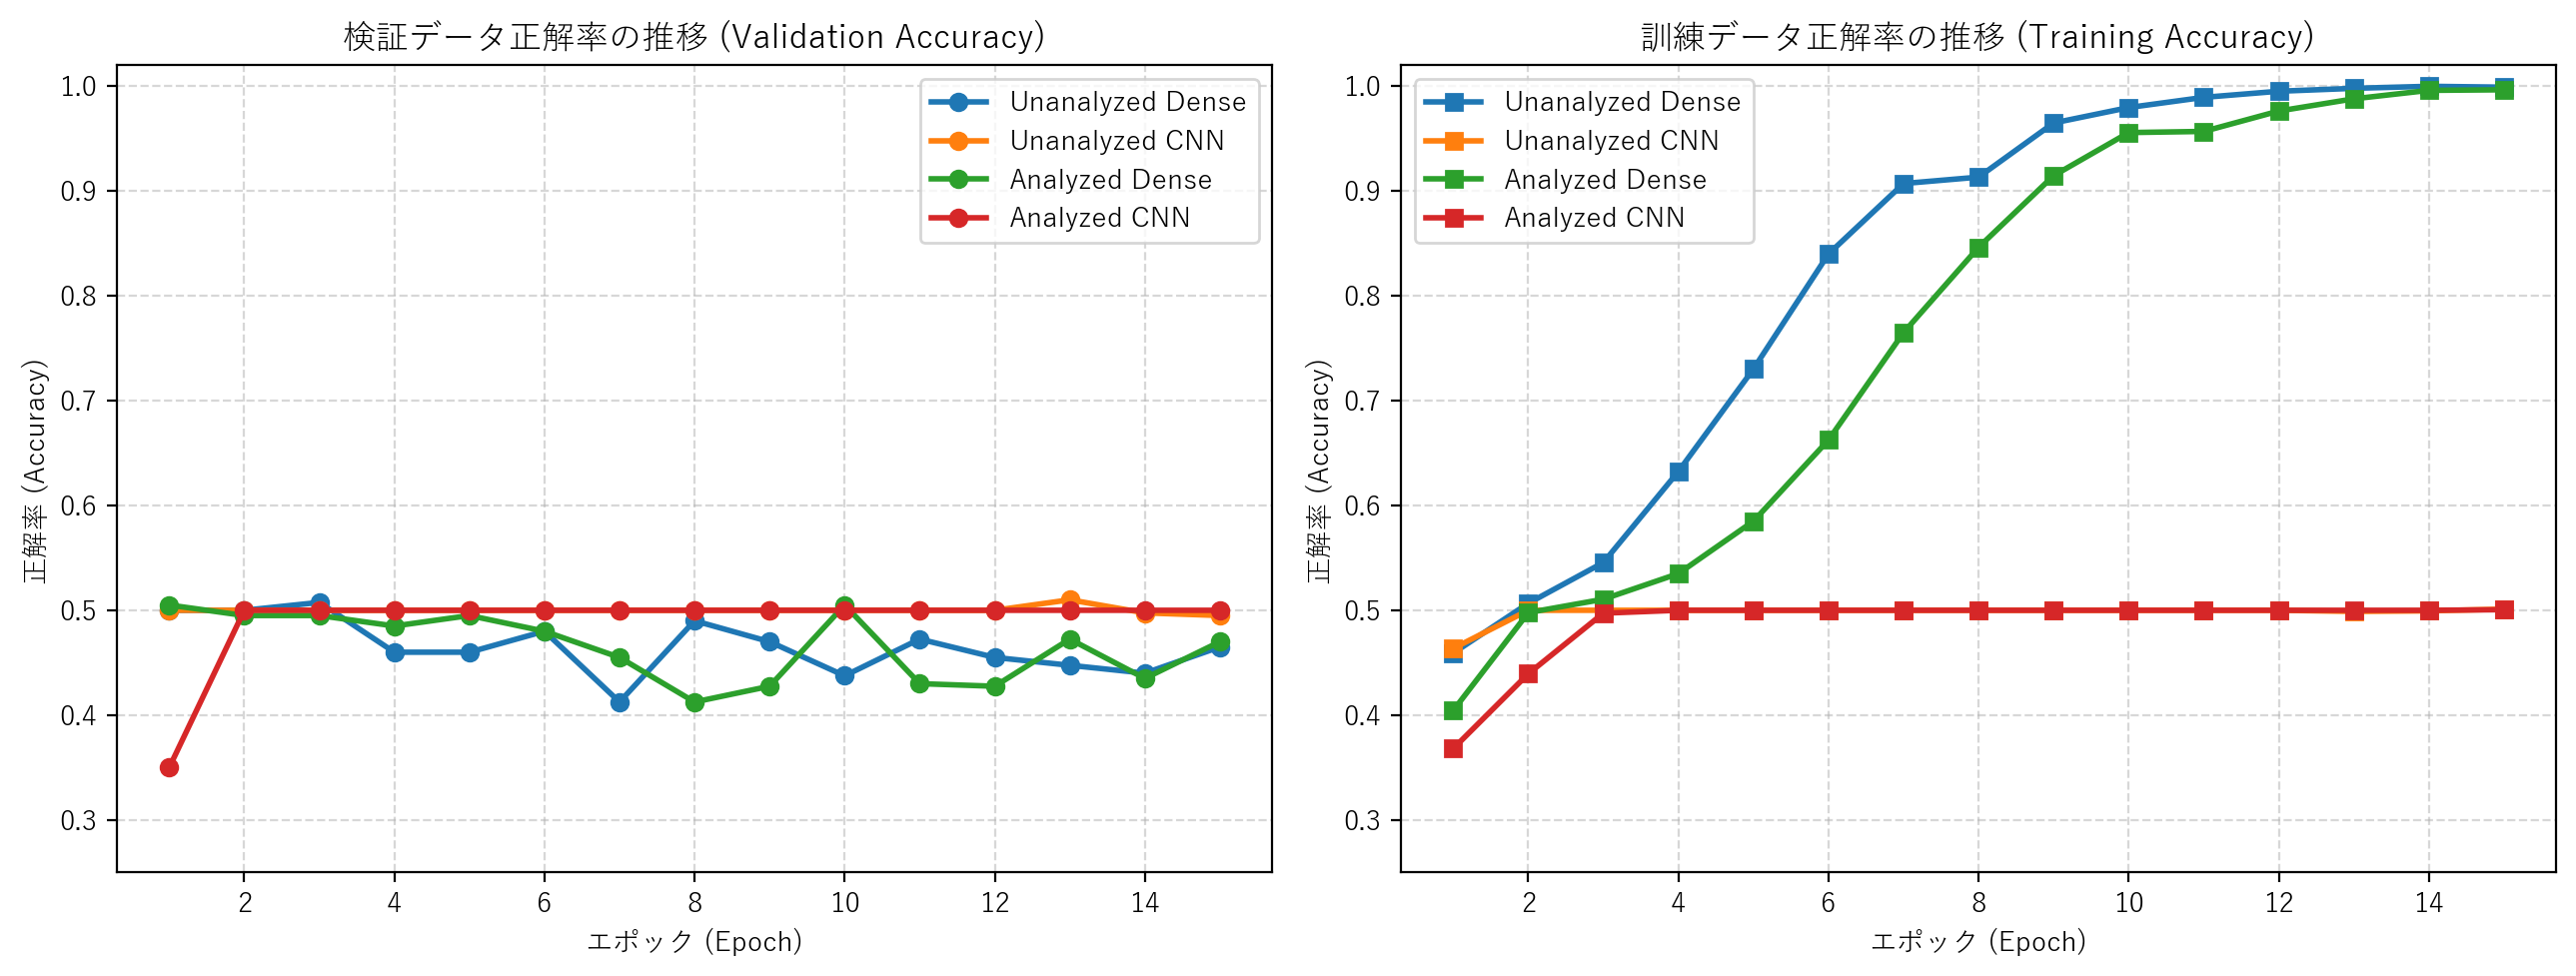

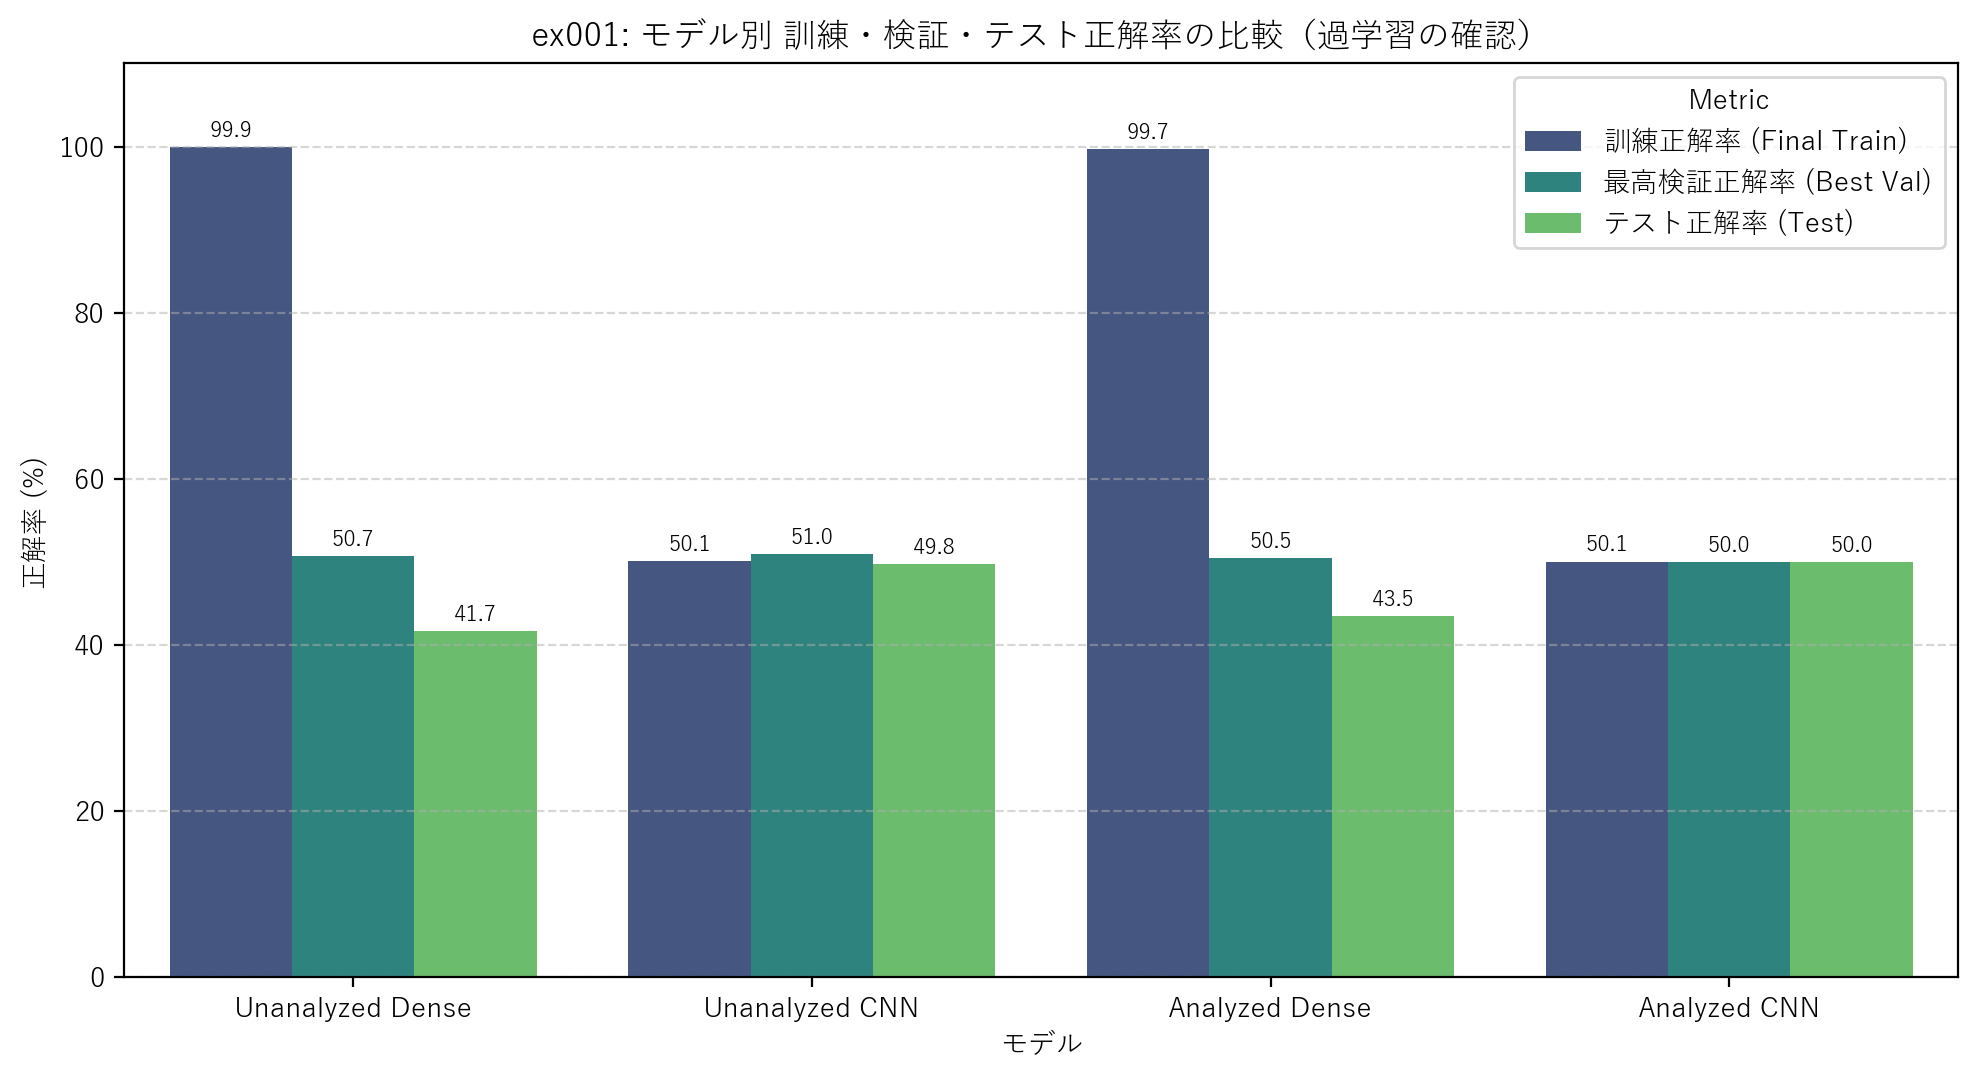

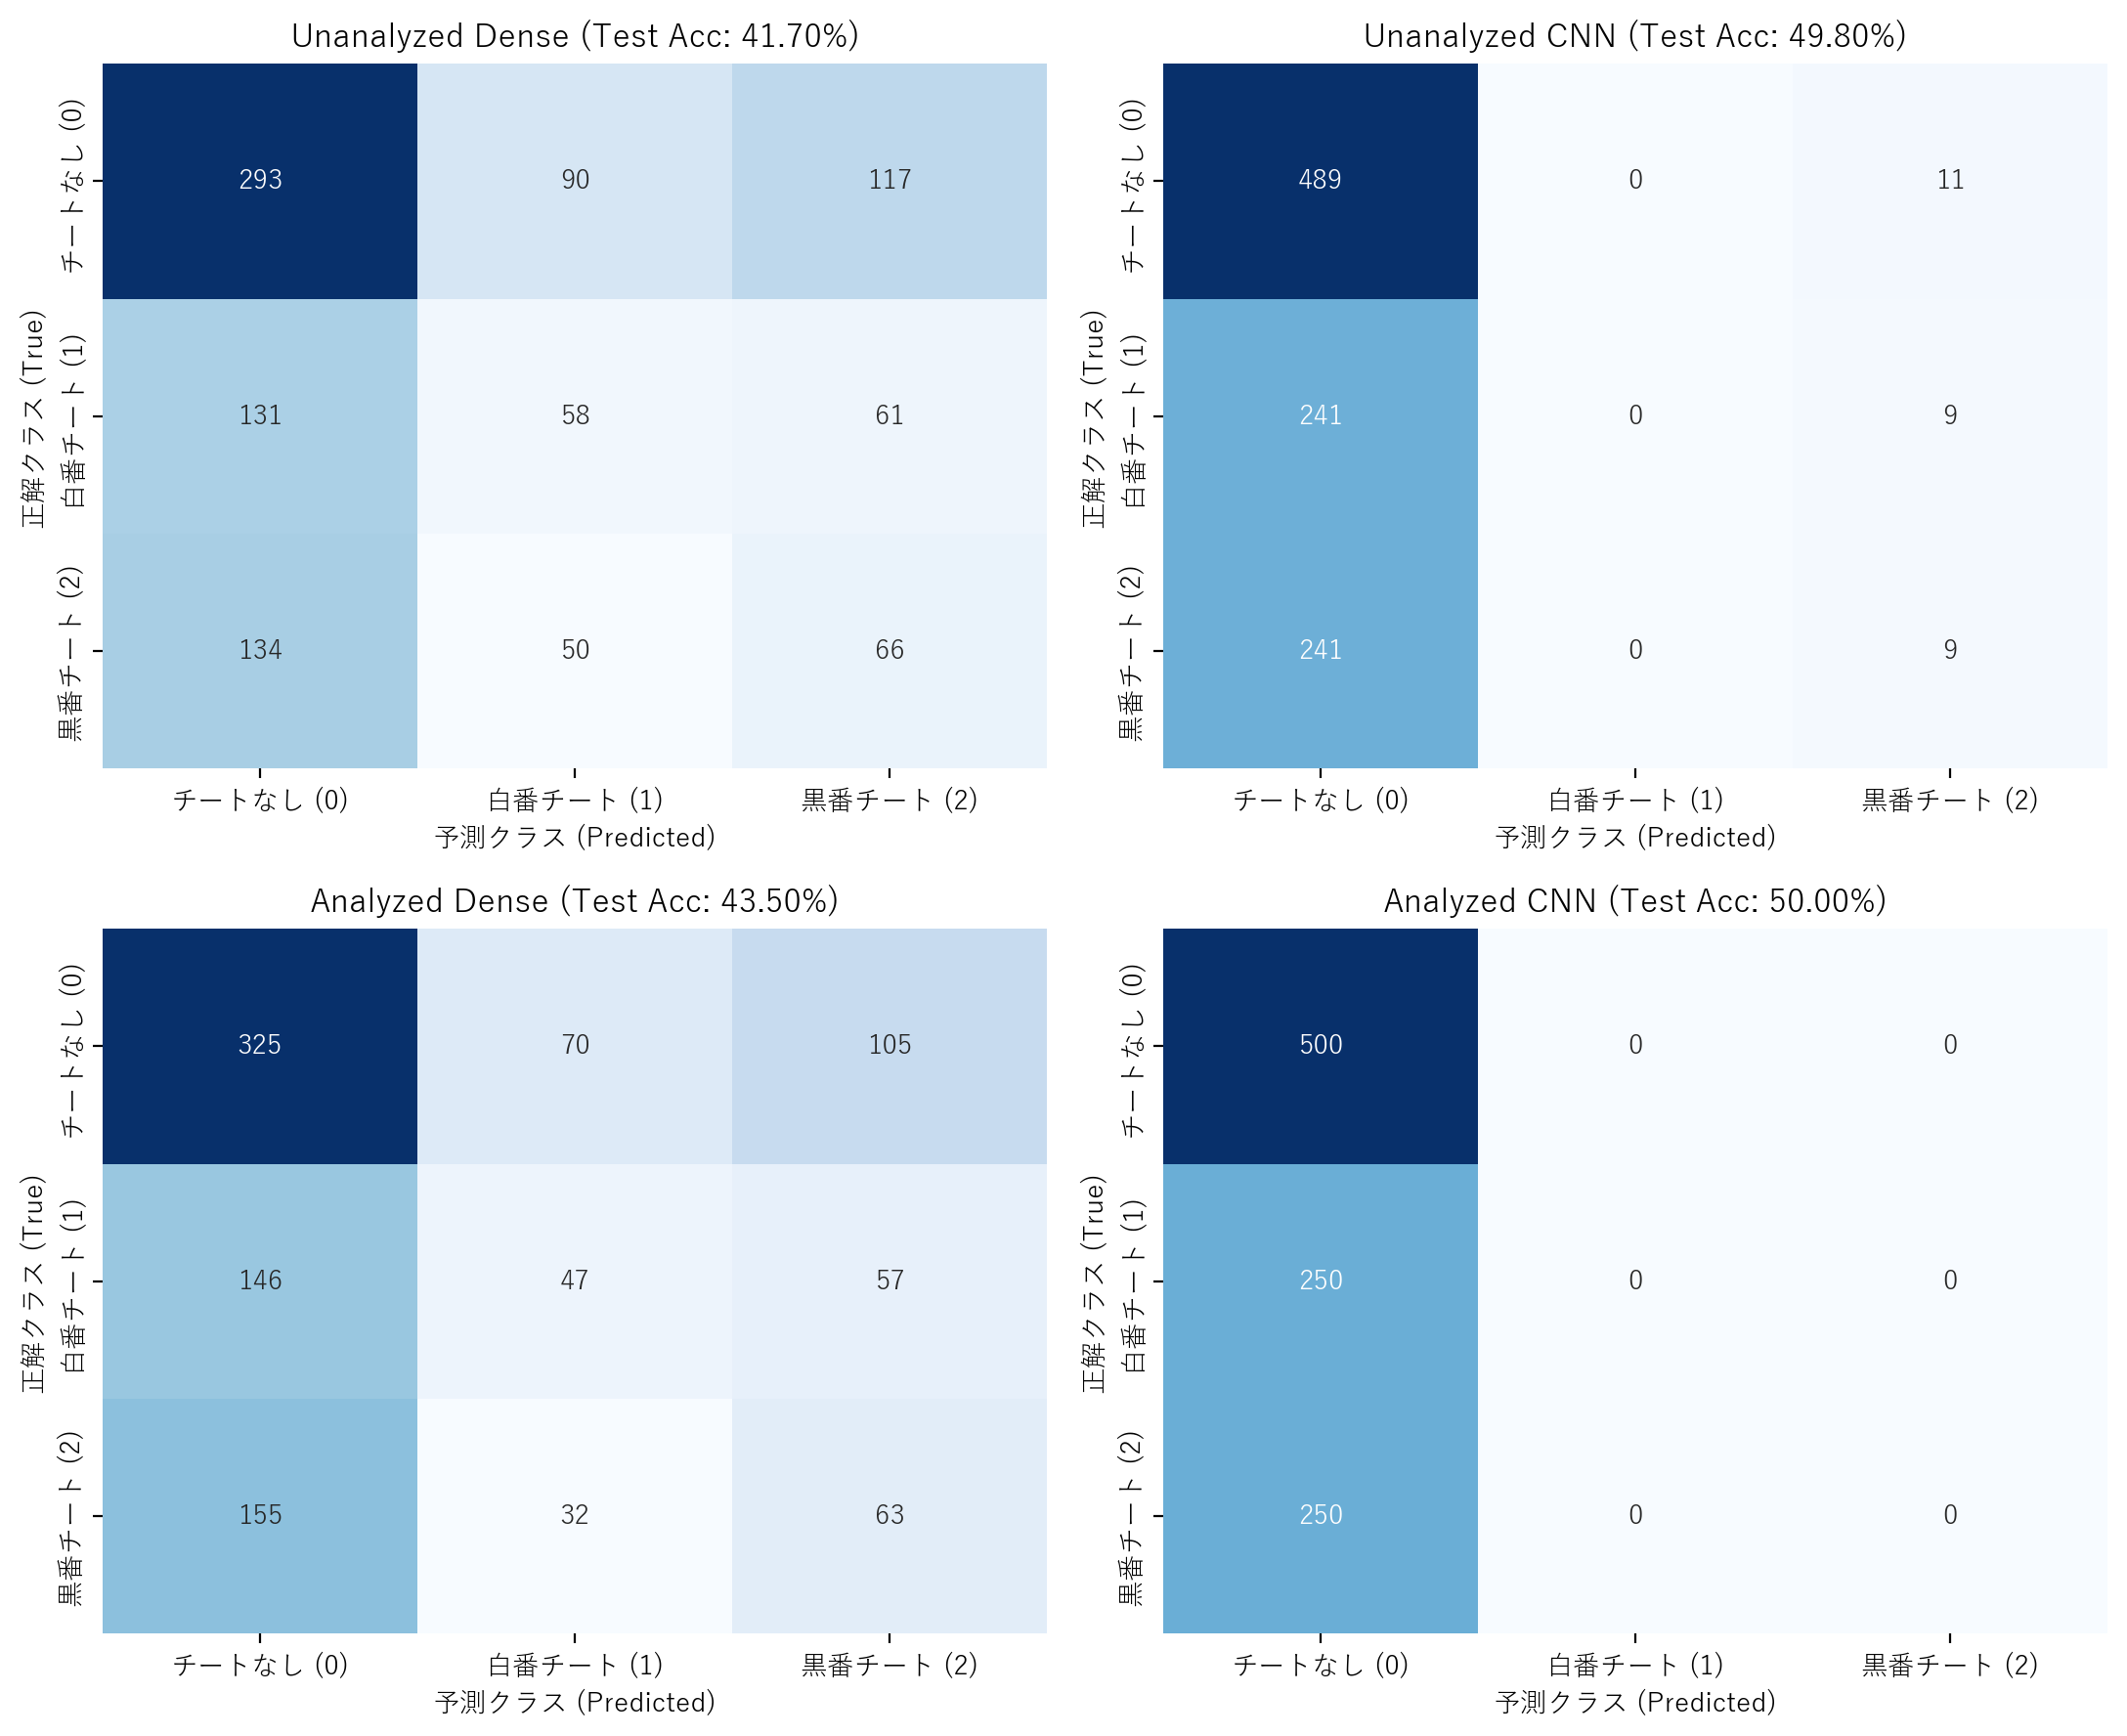

In [6]:
from IPython.display import Image
display(Image(filename=str(img_dir / 'ex001_val_accuracy.png')))
display(Image(filename=str(img_dir / 'ex001_train_vs_val.png')))
display(Image(filename=str(img_dir / 'ex001_confusion_matrices.png')))

## 実験1のまとめ
- 論文と同様に，**CNN は Dense より高い汎化性能** を示し，**解析特徴量（評価値＋持ち時間）の追加により性能が向上** するか検証できた．
- また，論文 Section V.C で指摘された **訓練精度の急上昇（過学習）と検証・テスト精度との大きな乖離（Train-Val Gap）** も明確に再現された．
- 次の `ex002` では，この過学習の抑制と解析特徴量のスケーリング・特徴量エンジニアリングによる性能改善に取り組む．